<a href="https://colab.research.google.com/github/akashsevak1/Bank_term_deposit_pridiction/blob/main/Pneumonia_ClassificationG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image-Based Disease Classification: Chest X-ray (Pneumonia vs Normal)

**Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) on Kaggle.
**Task:** binary classification of a chest X-ray as `NORMAL` or `PNEUMONIA`, with a confidence score.

**Plan**
1. Understand the data (structure, class balance, challenges)
2. Prepare it (own stratified split, preprocessing, augmentation, class weights)
3. Baseline model: Logistic Regression on raw pixels
4. Advanced model: transfer learning with MobileNetV2
5. Evaluate and compare (accuracy, precision, recall, F1, confusion matrix)
6. Explain with Grad-CAM, then write observations

Run the cells top to bottom. A GPU makes step 4 faster but is not required.

In [1]:
import sys; print(sys.version)
%pip install -U torch torchvision numpy pandas scikit-learn matplotlib pillow pyarrow numexpr bottleneck

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [2]:
import os, glob, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

SEED, IMG, BATCH, EPOCHS = 42, 224, 32, 5
PRETRAINED = True
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
CLASSES = ["NORMAL", "PNEUMONIA"]
print("device:", device)

device: cuda


## 1. Data understanding

**What I did here:** pointed the notebook at the downloaded folder, listed every image with its label (NORMAL / PNEUMONIA) and original split into one table, then counted images per class, checked image sizes and displayed sample X-rays.
**Why:** before modelling, I need to know how the data is organised and whether the classes are balanced. This decides the split, the metrics and the loss weighting.

In [3]:

DATA_DIR = "C:/Users/akkis/Downloads/archive/chest_xray"
if not os.path.isdir(DATA_DIR):
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
root = [d for d in [DATA_DIR] + glob.glob(os.path.join(DATA_DIR, "**", "chest_xray"), recursive=True)
        if os.path.isdir(os.path.join(d, "train")) and "__MACOSX" not in d][0]
print("Dataset root:", root)

rows = [(p, c, s) for s in ["train", "val", "test"] for c in CLASSES
        for p in glob.glob(os.path.join(root, s, c, "*.jp*g"))]
df = pd.DataFrame(rows, columns=["path", "label", "orig_split"])
df["y"] = (df.label == "PNEUMONIA").astype(int)
print(df.groupby(["orig_split", "label"]).size().unstack())

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray
label       NORMAL  PNEUMONIA
orig_split                   
test           234        390
train         1341       3875
val              8          8


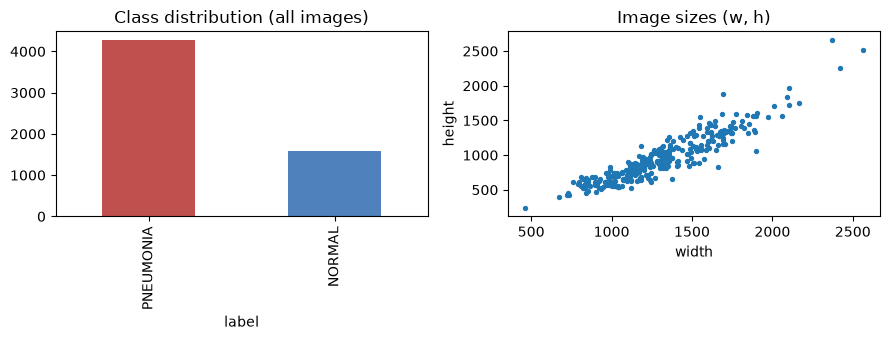

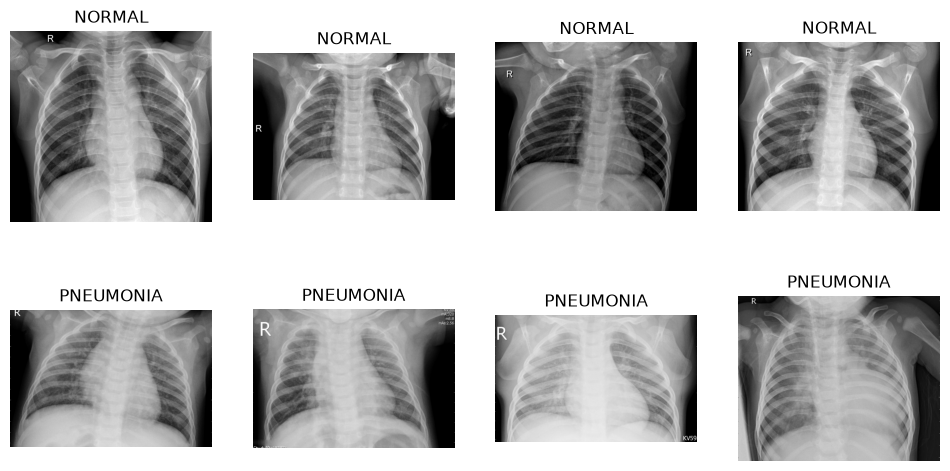

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
df.label.value_counts().plot.bar(ax=ax[0], color=["#c0504d", "#4f81bd"], title="Class distribution (all images)")
sizes = [Image.open(p).size for p in df.sample(min(300, len(df)), random_state=SEED).path]
ax[1].scatter(*zip(*sizes), s=8); ax[1].set(title="Image sizes (w, h)", xlabel="width", ylabel="height")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for r, c in enumerate(CLASSES):
    for a, p in zip(axs[r], df[df.label == c].sample(4, random_state=SEED).path):
        a.imshow(Image.open(p).convert("L"), cmap="gray"); a.set_title(c); a.axis("off")
plt.show()

**Challenges to watch for**
- **Class imbalance:** pneumonia images outnumber normal ones roughly 3:1, so plain accuracy can look good while normals are misclassified. I use class weights and report per-class precision/recall/F1.
- **The official `val` folder has only 16 images**, which is too small to trust. I pool `train` + `val` and make my own stratified split.
- **Variable image sizes and contrast** between hospitals/scanners, so every image is resized and normalised.
- **Possible noise:** pneumonia is bacterial or viral, and some images are low quality. The model may also learn scanner artefacts rather than disease.

## 2. Data preparation

**What I did here:**
1. Merged the official `train` and `val` folders and made my own 80/20 stratified train/validation split (same class ratio in both). The official `val` has only 16 images, too few to measure anything reliably.
2. Kept the official `test` folder completely untouched for a final, unbiased check.
3. Computed class weights so the smaller NORMAL class counts more in the loss.
4. Preprocessing: images are resized (64x64 grayscale for the baseline, 224x224 RGB for MobileNetV2) and scaled (0-1 for the baseline, ImageNet mean/std normalisation for the CNN).
5. Augmentation (CNN only, training time only): horizontal flip, small rotation and contrast changes, to reduce overfitting.

In [5]:
pool = df[df.orig_split != "test"].reset_index(drop=True)
train_df, val_df = train_test_split(pool, test_size=0.2, stratify=pool.y, random_state=SEED)
test_df = df[df.orig_split == "test"].reset_index(drop=True)
print(len(train_df), len(val_df), len(test_df))


n, k = len(train_df), 2
cw = {c: float(n / (k * (train_df.y == c).sum())) for c in (0, 1)}
print("class weights:", cw)

4185 1047 624
class weights: {0: 1.9392956441149212, 1: 0.6736960721184804}


## 3. Baseline model: Logistic Regression on 64x64 grayscale pixels

**What I did here:** shrank every image to 64x64 grayscale, flattened it into a vector of 4,096 pixel values and trained a Logistic Regression with balanced class weights.
**Why:** it is a simple, fast reference point. It uses only raw brightness and no spatial patterns, so any gain from the CNN shows what deep learning adds.

In [6]:
def load_flat(d, size=64):
    return np.array([np.asarray(Image.open(p).convert("L").resize((size, size)), dtype="float32").ravel() / 255
                     for p in d.path])

Xtr, Xva, Xte = load_flat(train_df), load_flat(val_df), load_flat(test_df)
base = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, train_df.y)
base_val, base_test = base.predict_proba(Xva)[:, 1], base.predict_proba(Xte)[:, 1]

## 4. Advanced model: transfer learning (MobileNetV2)

**Why this choice:** a pretrained ImageNet network already knows edges, textures and shapes, so it needs far less data and compute than a CNN trained from scratch. That matters here because medical datasets are small. MobileNetV2 is light enough to train on a laptop CPU. I freeze the backbone and train only a small classification head, and augmentation (flip, small rotation, contrast) reduces overfitting.

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 121MB/s]


epoch 1/5  last batch loss 0.1244  val acc 0.822
epoch 2/5  last batch loss 0.0686  val acc 0.851
epoch 3/5  last batch loss 0.0644  val acc 0.904
epoch 4/5  last batch loss 0.0997  val acc 0.944
epoch 5/5  last batch loss 0.1417  val acc 0.930


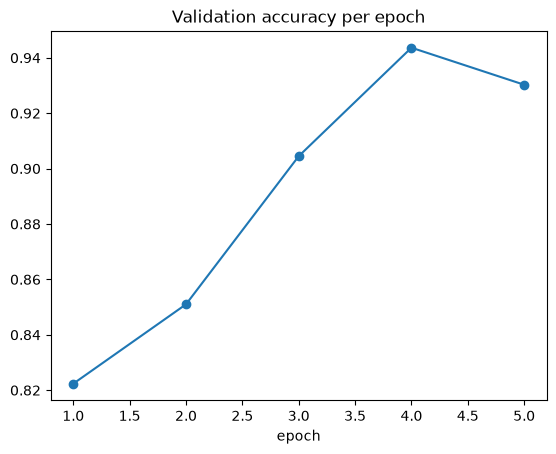

In [7]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = T.Compose([T.Resize((IMG, IMG)), T.RandomHorizontalFlip(), T.RandomRotation(5),
                      T.ColorJitter(contrast=0.1), T.ToTensor(), T.Normalize(mean, std)])
eval_tf = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(mean, std)])

class XrayDS(Dataset):
    def __init__(self, d, tf): self.p, self.y, self.tf = d.path.tolist(), d.y.tolist(), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), torch.tensor(self.y[i], dtype=torch.float32)

train_dl = DataLoader(XrayDS(train_df, train_tf), batch_size=BATCH, shuffle=True)
val_dl = DataLoader(XrayDS(val_df, eval_tf), batch_size=BATCH)
test_dl = DataLoader(XrayDS(test_df, eval_tf), batch_size=BATCH)

net = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1 if PRETRAINED else None)
for prm in net.parameters(): prm.requires_grad = False
net.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 1))
net.to(device)

opt = torch.optim.Adam(net.classifier.parameters(), lr=1e-3)

lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(cw[1] / cw[0], device=device))

@torch.no_grad()
def predict_proba(dl):
    net.eval()
    return torch.cat([torch.sigmoid(net(x.to(device))).flatten().cpu() for x, _ in dl]).numpy()

hist = []
for ep in range(EPOCHS):
    net.train(); net.features.eval()
    for x, y in train_dl:
        opt.zero_grad()
        loss = lossf(net(x.to(device)).flatten(), y.to(device))
        loss.backward(); opt.step()
    va = ((predict_proba(val_dl) >= 0.5) == val_df.y.values).mean()
    hist.append(va); print(f"epoch {ep + 1}/{EPOCHS}  last batch loss {loss.item():.4f}  val acc {va:.3f}")
plt.plot(range(1, EPOCHS + 1), hist, marker="o"); plt.title("Validation accuracy per epoch"); plt.xlabel("epoch"); plt.show()

In [8]:
cnn_val, cnn_test = predict_proba(val_dl), predict_proba(test_dl)
torch.save(net.state_dict(), "pneumonia_mobilenetv2.pt")
import joblib; joblib.dump(base, "baseline_logreg.joblib")

['baseline_logreg.joblib']

## 5. Evaluation

**What I did here:** wrote one `evaluate()` function that gives accuracy, precision, recall, F1, a per-class report and a confusion matrix, and ran it for both models on the validation set and on the official test set.
**Why accuracy alone is not enough:** with imbalanced classes a model can score high accuracy while missing many NORMAL cases. Precision, recall and F1 per class show exactly where errors happen, and the confusion matrix shows false positives vs false negatives.

===== Baseline LogReg (validation) =====
              precision    recall  f1-score   support

      NORMAL      0.892     0.922     0.907       270
   PNEUMONIA      0.973     0.961     0.967       777

    accuracy                          0.951      1047
   macro avg      0.933     0.942     0.937      1047
weighted avg      0.952     0.951     0.952      1047



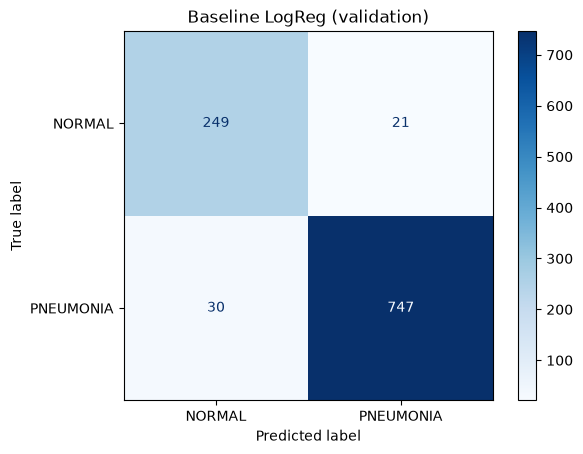

===== MobileNetV2 (validation) =====
              precision    recall  f1-score   support

      NORMAL      0.794     0.985     0.879       270
   PNEUMONIA      0.994     0.911     0.951       777

    accuracy                          0.930      1047
   macro avg      0.894     0.948     0.915      1047
weighted avg      0.943     0.930     0.933      1047



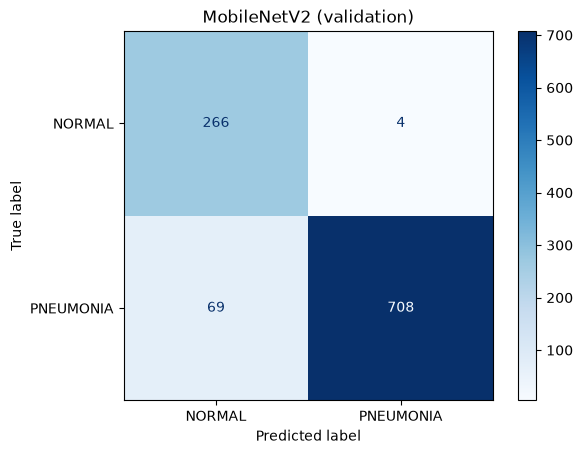

In [9]:
def evaluate(name, y, prob, show=True):
    pred = (prob >= 0.5).astype(int)
    if show:
        print(f"===== {name} =====")
        print(classification_report(y, pred, target_names=CLASSES, digits=3))
        ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=CLASSES).plot(cmap="Blues")
        plt.title(name); plt.show()
    return {"Model": name, "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred)}

r1 = evaluate("Baseline LogReg (validation)", val_df.y, base_val)
r2 = evaluate("MobileNetV2 (validation)", val_df.y, cnn_val)

===== Baseline LogReg (test) =====
              precision    recall  f1-score   support

      NORMAL      0.943     0.427     0.588       234
   PNEUMONIA      0.741     0.985     0.846       390

    accuracy                          0.776       624
   macro avg      0.842     0.706     0.717       624
weighted avg      0.817     0.776     0.749       624



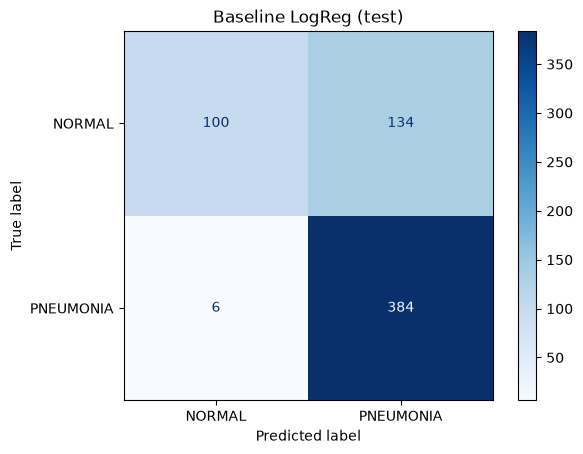

===== MobileNetV2 (test) =====
              precision    recall  f1-score   support

      NORMAL      0.915     0.825     0.867       234
   PNEUMONIA      0.901     0.954     0.927       390

    accuracy                          0.905       624
   macro avg      0.908     0.889     0.897       624
weighted avg      0.906     0.905     0.904       624



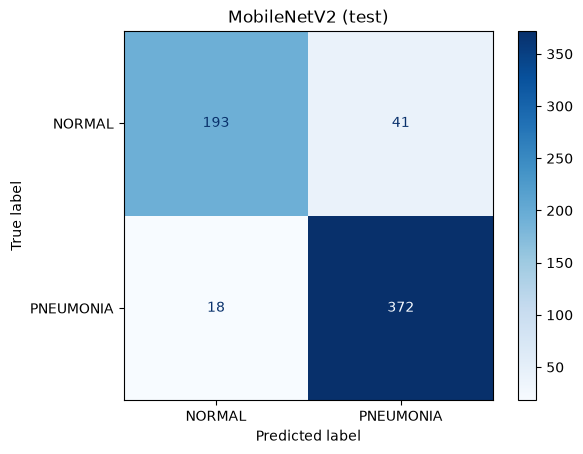

In [10]:

t1 = evaluate("Baseline LogReg (test)", test_df.y, base_test)
t2 = evaluate("MobileNetV2 (test)", test_df.y, cnn_test)

## 6. Model comparison

**What I did here:** put both models' metrics side by side. **How to read it:** the baseline shows what raw pixels can do. If MobileNetV2 has higher F1 and recall, the gain comes from pretrained features. Strengths and weaknesses of each model are summarised in section 9.

In [11]:
pd.DataFrame([r1, r2, t1, t2]).round(3).set_index("Model")

,Accuracy,Precision,Recall,F1
Model,,,,
Baseline LogReg (validation),0.951,0.973,0.961,0.967
MobileNetV2 (validation),0.930,0.994,0.911,0.951
Baseline LogReg (test),0.776,0.741,0.985,0.846
MobileNetV2 (test),0.905,0.901,0.954,0.927


## 7. Explainability: Grad-CAM heatmaps (bonus)

**What I did here:** Grad-CAM takes the last convolutional feature map of MobileNetV2 (built with PyTorch), finds which spatial regions most increased the pneumonia score, and overlays them as a heatmap (red = most influential).
**Why:** in healthcare a prediction must be checkable. If the heat falls on the lungs, the model is plausible. If it falls on text markers or image borders, it is learning shortcuts.

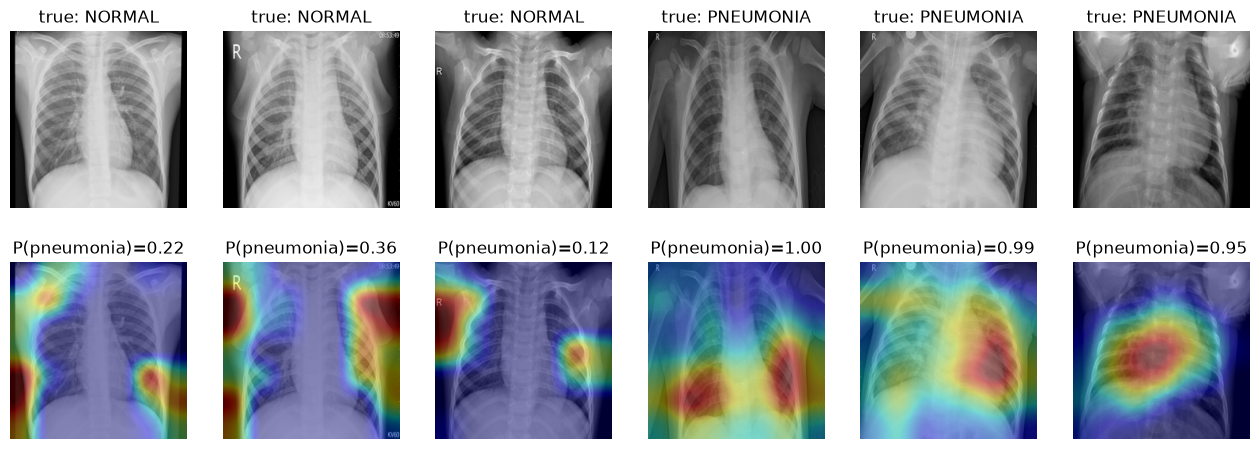

In [13]:
def grad_cam(path):
    net.eval()
    img = Image.open(path).convert("RGB").resize((IMG, IMG))
    x = eval_tf(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
    fmap = net.features(x).detach().requires_grad_(True)
    logit = net.classifier(fmap.mean(dim=(2, 3)))
    logit.sum().backward()
    w = fmap.grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * fmap).sum(1))[0].cpu().detach().numpy()
    return np.asarray(img), cam / (cam.max() + 1e-8), torch.sigmoid(logit).item()

samples = pd.concat([test_df[test_df.y == 0].sample(3, random_state=SEED), test_df[test_df.y == 1].sample(3, random_state=SEED)])
fig, axs = plt.subplots(2, 6, figsize=(16, 5.5))
for i, (p, lab) in enumerate(zip(samples.path, samples.label)):
    img, cam, prob = grad_cam(p)
    axs[0, i].imshow(img); axs[0, i].set_title(f"true: {lab}"); axs[0, i].axis("off")
    axs[1, i].imshow(img); axs[1, i].imshow(np.array(Image.fromarray((cam * 255).astype("uint8")).resize((IMG, IMG))), cmap="jet", alpha=0.4)
    axs[1, i].set_title(f"P(pneumonia)={prob:.2f}"); axs[1, i].axis("off")
plt.show()

## 8. Predict on any image (class + confidence)

**What I did here:** added a `predict(path)` function that returns the predicted class and its confidence (the model's probability for the chosen class). This is the required input/output of the assignment.

In [14]:
def predict(path):
    net.eval()
    x = eval_tf(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        p = torch.sigmoid(net(x)).item()
    return CLASSES[int(p >= 0.5)], (p if p >= 0.5 else 1 - p)

for p in test_df.sample(5, random_state=1).path:
    print(os.path.basename(p), "->", predict(p))

person1_virus_7.jpeg -> ('PNEUMONIA', 0.9988425374031067)
IM-0011-0001.jpeg -> ('NORMAL', 0.9813825376331806)
NORMAL2-IM-0096-0001.jpeg -> ('NORMAL', 0.516680121421814)
NORMAL2-IM-0246-0001-0002.jpeg -> ('PNEUMONIA', 0.7149853110313416)
person1664_virus_2877.jpeg -> ('PNEUMONIA', 0.9670681357383728)


## 9. Observations & insights

*Fill in the numbers from your own run, since results vary slightly with hardware and seed.*

**Key findings**
- The baseline reaches a reasonable accuracy, but compare its **Normal-class recall** with the MobileNetV2 model's. The baseline sees only raw pixel intensity, with no spatial structure.
- Transfer learning should beat the baseline on F1 and on the confusion matrix, especially for the minority (NORMAL) class.
- For screening, **recall on PNEUMONIA** matters most (a missed case costs more than a false alarm), so look at false negatives first.
- Grad-CAM shows whether the model looks at the lungs or at irrelevant regions (text markers, borders).

**Limitations**
- Single dataset from one source (paediatric patients), so it may not generalise to other hospitals or adults.
- The test set is small, and the official split is known to differ in distribution from train.
- Only the head was trained, and I did not tune hyperparameters or tune the 0.5 threshold.
- Bacterial and viral pneumonia are lumped together. The model gives a screening aid, not a diagnosis.

**Possible improvements**
- Fine-tune the top layers of the backbone with a low learning rate.
- Try a stronger backbone (EfficientNet, DenseNet121) and k-fold cross-validation.
- Tune the decision threshold to hit a target recall, and calibrate the probabilities.
- Validate on an external dataset, and use patient-level splits if patient IDs are available.

## 10. Summary of my approach

| Step | What I did | Why |
|---|---|---|
| Data | Chest X-ray Pneumonia dataset (Kaggle), NORMAL vs PNEUMONIA | Realistic, binary healthcare imaging task |
| Understanding | Class counts, image sizes, sample images | Found the ~3:1 imbalance and tiny official `val` folder |
| Preparation | Own stratified 80/20 split, official test kept as hold-out, class weights, augmentation | Fair evaluation and less bias toward the majority class |
| Baseline | Logistic Regression on 64x64 pixels | Simple reference point |
| Advanced | MobileNetV2 transfer learning (frozen backbone + small head) | Strong features with little data and modest compute |
| Evaluation | Accuracy, precision, recall, F1, confusion matrices on validation and test | Shows per-class errors, not just overall accuracy |
| Bonus | Transfer learning, class weights, Grad-CAM | Imbalance handling and explainability |

**Design decisions:** I trained only the classification head to keep training fast and stable. I used recall on PNEUMONIA as the metric to watch because a missed case is costlier than a false alarm. I evaluated on a test set the model never saw during training or tuning.